# Batch correction with scANVI (semi-supervised)

scANVI (Xu *et al.*, *Mol Syst Biol* 2021) adds a cell-type classifier to
scVI and trains it on the cells that carry a label. Cells without a label get
a placeholder category (here `'Unknown'`); scANVI batch-corrects all cells and
predicts labels for the unknowns. The latent lands in `adata.obsm['X_scANVI']`
and the predictions in `adata.obs['scANVI_predicted_labels']`.


> **Backend.** Since omicverse 2.4 the scVI family (`'scVI'`, `'scANVI'`,
> `'totalVI'`) runs on **`ov.vi`** — omicverse's own PyTorch implementation
> (scvi-tools-compatible API and defaults, no scvi-tools / Lightning
> dependency). It trains on in-memory AnnData, disk-backed AnnDataOOM
> (`ov.read(path, storage='disk')`) and Dask-backed AnnData (GPU mode). See
> [t_vi](../t_vi.ipynb) for the direct `ov.vi` API, disk and GPU training.


This is one of the **omicverse batch-correction zoo** tutorials. See
[batch/index](../index.md) for the overview / decision tree, or
[../t_single_batch](../t_single_batch.ipynb) for the side-by-side comparison of
every backend.

## Load the NeurIPS 2021 bone-marrow data (3 donors)

Bone-marrow mononuclear cells from the NeurIPS 2021 multimodal single-cell
integration benchmark (Luecken *et al.*, NeurIPS Datasets & Benchmarks 2021),
gene-expression part of the CITE-seq arm: three donors measured at three
different sites (`s1d3`, `s2d1`, `s3d7`) — each donor/site is one batch — with
the authors' cell-type annotation in `obs['cell_type']`. The files store raw
counts in `layers['counts']` and normalised values in `X`; scVI-family models
need the **raw counts**, so we put them back into `X` before preprocessing.

The zoo notebooks use a 6 000-cell random subsample so every backend runs in
minutes; [t_vi](../t_vi.ipynb) uses all 27 423 cells.

In [1]:
import omicverse as ov
import anndata as ad
import numpy as np
import pandas as pd
ov.style()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 1
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: unknown   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [2]:
adata1 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932005', filename='neurips2021_s1d3.h5ad')
adata2 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932008', filename='neurips2021_s2d1.h5ad')
adata3 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932011', filename='neurips2021_s3d7.h5ad')

⚠️ File ./data/neurips2021_s1d3.h5ad already exists
 Loading data from ./data/neurips2021_s1d3.h5ad


✅ Successfully loaded: 5935 cells × 13953 genes
⚠️ File ./data/neurips2021_s2d1.h5ad already exists
 Loading data from ./data/neurips2021_s2d1.h5ad


✅ Successfully loaded: 10258 cells × 13953 genes
⚠️ File ./data/neurips2021_s3d7.h5ad already exists
 Loading data from ./data/neurips2021_s3d7.h5ad


✅ Successfully loaded: 11230 cells × 13953 genes


In [3]:
adata = ad.concat([adata1, adata2, adata3], merge='same')
adata.X = adata.layers['counts'].copy()   # raw counts back into X
adata.obs['batch'] = adata.obs['batch'].astype('category')
adata

AnnData object with n_obs × n_vars = 27423 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train'
    var: 'feature_types', 'gene_id'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
    layers: 'counts', None (.X)

In [4]:
sel = np.random.default_rng(0).choice(adata.n_obs, 6000, replace=False)
adata = adata[np.sort(sel)].copy()
adata.obs['batch'].value_counts()

batch
s3d7    2442
s2d1    2270
s1d3    1288
Name: count, dtype: int64

## Preprocess

The zoo-wide pipeline: QC → size normalisation + log → 2 000 HVGs (Pearson
residuals) → scaled PCA. `ov.pp.preprocess` keeps the raw counts in
`layers['counts']`, which is what the scVI family trains on. The NeurIPS cells
are already filtered, so the QC thresholds are loose and doublet detection is
skipped.

In [5]:
adata = ov.pp.qc(adata, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 250},
                 doublets=False)
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', n_HVGs=2000)

🖥️ Using CPU mode for QC...
   Auto-detected mitochondrial prefix: 'MT-'

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 94                 │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 11                 │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴────────────────────┘

   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range 

   ✓ Final filtering: 0 cells, 0 genes removed

📊 Step 4: Doublet detection disabled

╭─ SUMMARY: qc ──────────────────────────────────────────────────────╮
│  Duration: 0.3232s                                                 │
│  Shape:    6,000 x 13,953 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ cell_complexity (float)                              │
│           │ ✚ detected_genes (int)                                 │
│           │ ✚ hb_perc (float)                                      │
│           │ ✚ mito_perc (float)                                    │
│           │ ✚ nUMIs (float)                                        │
│           │ ✚ n_counts (float)                                     │
│           │ ✚ n_genes (int)                                 


✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 13,953 total (14.3%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 0.74 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ───────────────────

In [6]:
adata.raw = adata
adata = adata[:, adata.var.highly_variable_features].copy()
ov.pp.scale(adata)
ov.pp.pca(adata, layer='scaled', n_pcs=30)


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.0333s                                                 │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (array, 5895x2000)                            │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
computing PCA🔍
    with n_comps=30
   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (5895, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (1.53s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 1.5324s                                                 │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 5895x30)                               │
│           │ ✚ scaled|original|X_pca (array, 5895x30)               │
│         

## Uncorrected baseline

UMAP of the uncorrected PCA: cells separate by donor within most cell types —
the batch effect we want to remove.

🖥️ Using Scanpy CPU to calculate neighbors...

🔍 K-Nearest Neighbors Graph Construction:
   Mode: cpu
   Neighbors: 15
   Method: umap
   Metric: euclidean
   Representation: scaled|original|X_pca
   🔍 Computing neighbor distances...


   🔍 Computing connectivity matrix...
   💡 Using UMAP-style connectivity
   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 5,895 cells with 15 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 0.3854s                                                 │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ neighbors                                            │
│           │ └─ params: {'n_neighbors': 15, 'method': 'umap', 'random_s...│
│                        

   🔍 Computing UMAP parameters...
   🔍 Computing UMAP embedding (classic method)...



✅ UMAP Dimensionality Reduction Completed Successfully!
   ✓ Embedding shape: 5,895 cells × 2 dimensions
   ✓ Results added to AnnData object:
     • 'X_umap': UMAP coordinates (adata.obsm)
     • 'umap': UMAP parameters (adata.uns)
✅ UMAP completed successfully.

╭─ SUMMARY: umap ────────────────────────────────────────────────────╮
│  Duration: 9.6029s                                                 │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ umap                                                 │
│           │ └─ params: {'a': np.float64(0.5830300203414425), 'b': np.f...│
│                                                                    │
│  ● OBSM   │ ✚ X_umap (array, 5895x2)                               │
│                 

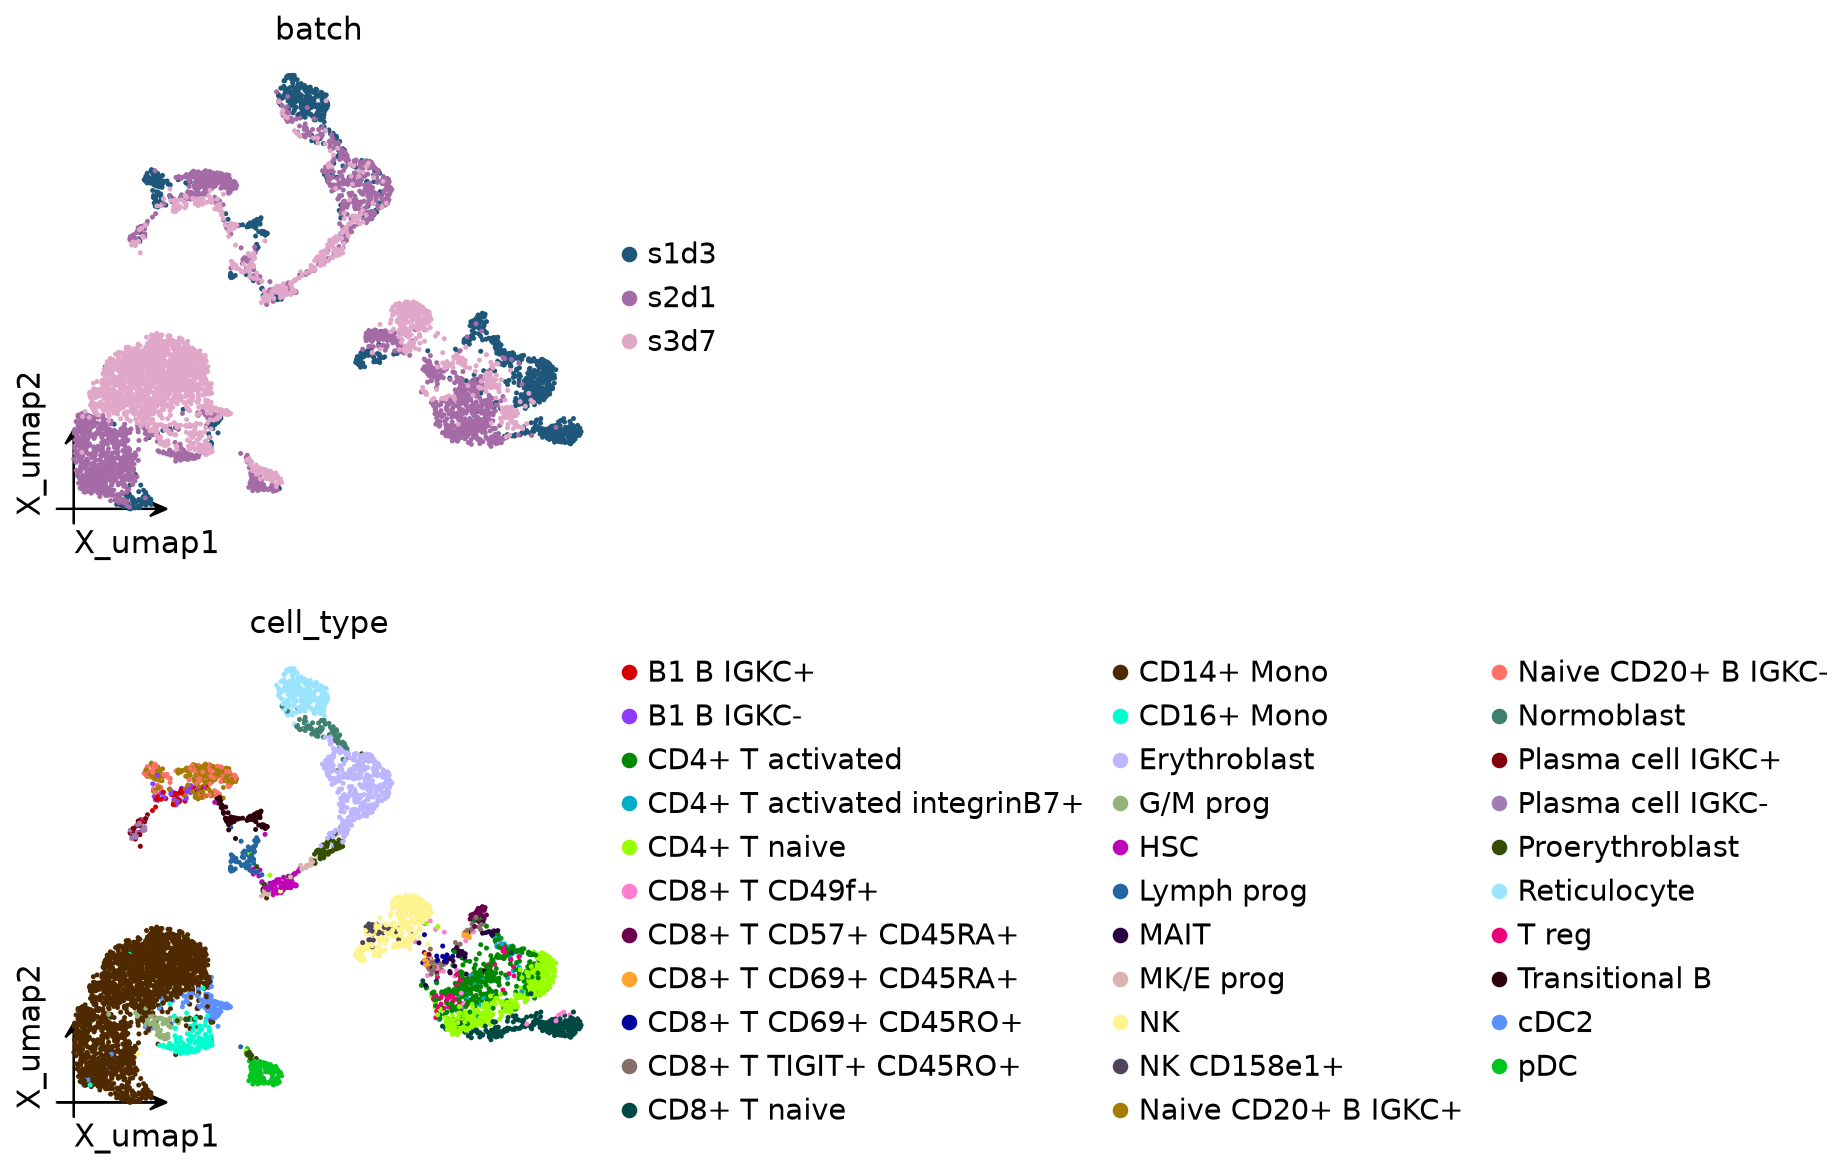

In [7]:
ov.pp.neighbors(adata, use_rep='scaled|original|X_pca', n_neighbors=15)
ov.pp.umap(adata)
ov.pl.embedding(adata, basis='X_umap', color=['batch', 'cell_type'],
                frameon='small', wspace=0.65)

## Hide 20 % of the labels

To mimic a partially annotated dataset we hide the label of every 5th cell
(`'Unknown'`); scANVI learns from the other 80 % and predicts the hidden ones,
which we can then check against the authors' annotation.

In [8]:
labels = adata.obs['cell_type'].astype(str)
labels.iloc[::5] = 'Unknown'
adata.obs['celltype_for_scanvi'] = pd.Categorical(labels)
adata.obs['celltype_for_scanvi'].value_counts().head()

celltype_for_scanvi
CD14+ Mono      1663
Unknown         1179
CD4+ T naive     355
Erythroblast     332
NK               286
Name: count, dtype: int64

## Run `ov.single.batch_correction(methods='scANVI')`

`labels_key` and `unlabeled_category` are required. Same architecture as the
scVI zoo notebook (2 layers, 30-d latent); scANVI is trained from scratch here
(400 epochs for 6 000 cells; see [t_vi](../t_vi.ipynb) for the faster
`SCANVI.from_scvi_model` route).

In [9]:
model = ov.single.batch_correction(adata, batch_key='batch', methods='scANVI',
                                   labels_key='celltype_for_scanvi',
                                   unlabeled_category='Unknown',
                                   n_layers=2, n_latent=30, check_val_every_n_epoch=10)
model

...Begin using scANVI to correct batch effect


Training:   0%|          | 0/400 [00:00<?, ?epoch/s]


╭─ SUMMARY: batch_correction ────────────────────────────────────────╮
│  Duration: 53.7544s                                                │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ scANVI_predicted_labels (str)                        │
│                                                                    │
│  ● OBSM   │ ✚ X_scANVI (array, 5895x30)                            │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯


SCANVI(n_obs=5895, n_vars=2000, n_batch=3, n_labels=32, layer='counts', trained=True)

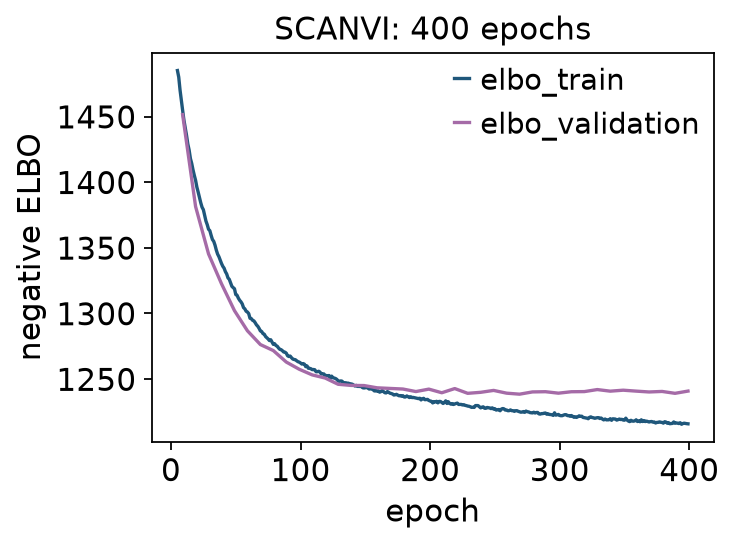

In [10]:
ov.vi.plot_history(model, skip_first=5);

## Label transfer accuracy on the hidden cells

In [11]:
hidden = (adata.obs['celltype_for_scanvi'] == 'Unknown').values
pred = adata.obs['scANVI_predicted_labels'].astype(str).values
truth = adata.obs['cell_type'].astype(str).values
print(f'accuracy on {hidden.sum()} hidden cells: {(pred[hidden] == truth[hidden]).mean():.3f}')

accuracy on 1179 hidden cells: 0.907


About 91 % of the hidden cells get their author label back. The per-type
breakdown shows where the misses are — between closely related fine-grained
states such as naive vs. activated CD4⁺ T cells or IGKC⁺ vs. IGKC⁻ naive B
cells:

In [12]:
res = pd.DataFrame({'cell_type': truth[hidden], 'correct': pred[hidden] == truth[hidden]})
res.groupby('cell_type')['correct'].agg(['mean', 'size']).sort_values('size', ascending=False).head(15).round(3)

                      mean  size
cell_type                       
CD14+ Mono           0.983   422
CD4+ T naive         0.909    88
NK                   0.866    82
Erythroblast         0.931    72
CD4+ T activated     0.723    65
CD8+ T naive         0.944    54
Reticulocyte         1.000    54
Naive CD20+ B IGKC+  0.769    39
Naive CD20+ B IGKC-  0.861    36
pDC                  1.000    33
CD16+ Mono           0.962    26
cDC2                 0.880    25
HSC                  0.913    23
Lymph prog           0.909    22
Transitional B       1.000    19

## Corrected embedding

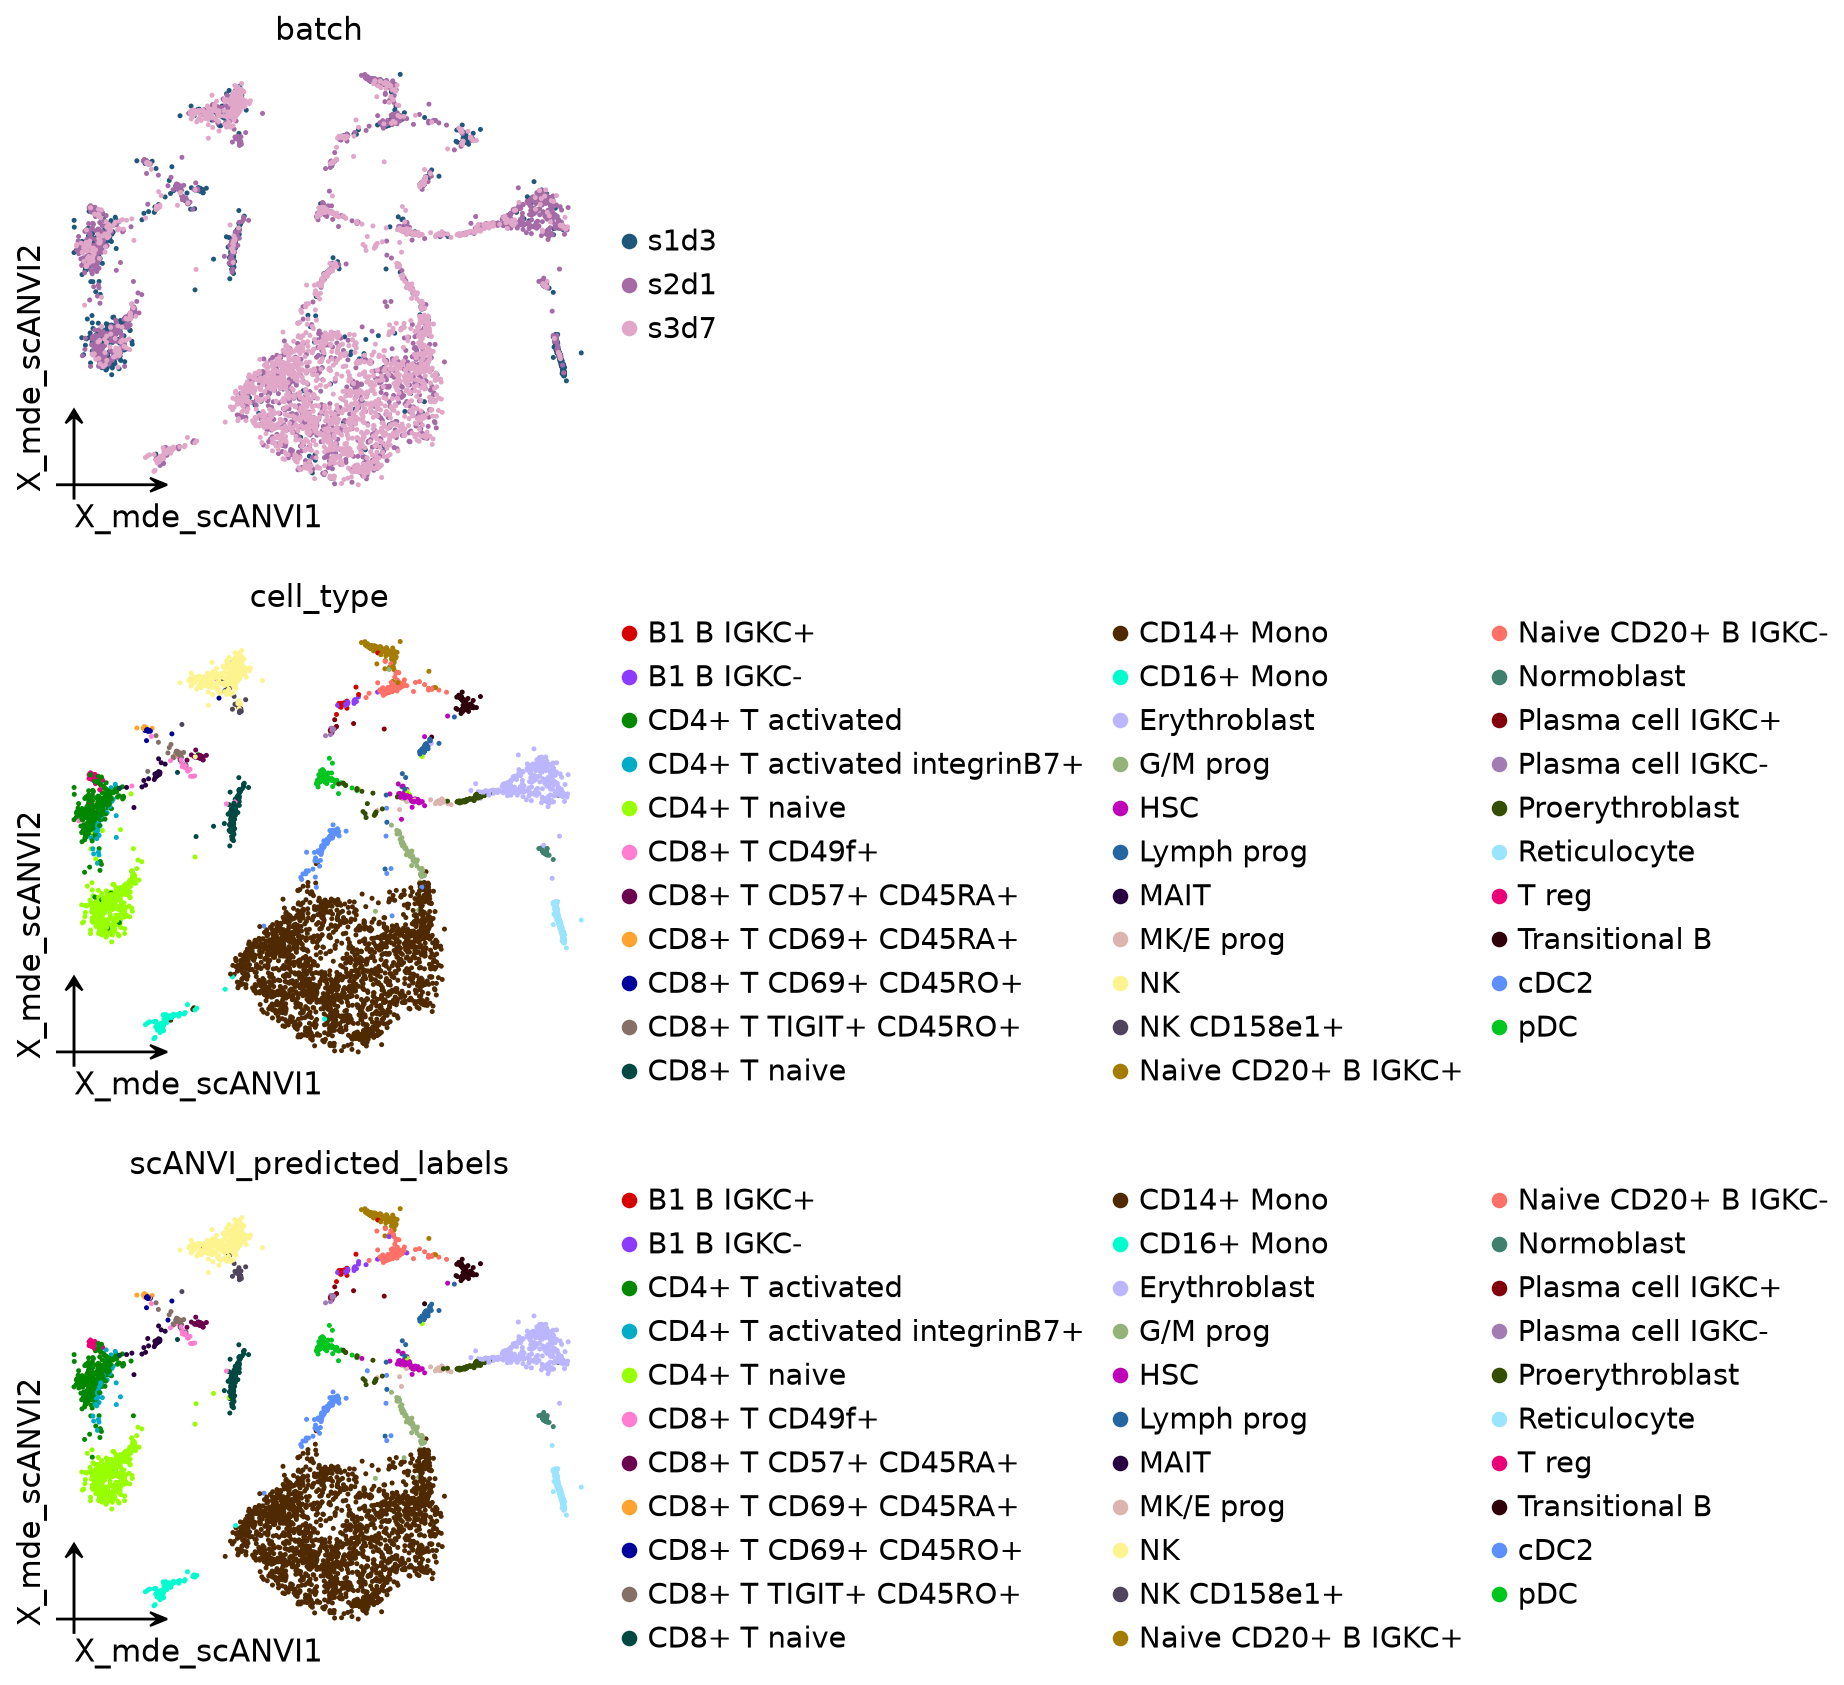

In [13]:
adata.obsm['X_mde_scANVI'] = ov.vi.mde(adata.obsm['X_scANVI'])
cats = adata.obs['cell_type'].cat.categories   # same categories -> same colours
adata.obs['scANVI_predicted_labels'] = pd.Categorical(pred, categories=cats)
ov.pl.embedding(adata, basis='X_mde_scANVI',
                color=['batch', 'cell_type', 'scANVI_predicted_labels'],
                frameon='small', wspace=0.65, ncols=2)

In [14]:
scores = ov.vi.integration_metrics(adata, ['X_pca', 'X_scANVI'], batch_key='batch',
                                   label_key='cell_type', n_jobs=16)
scores.round(3)

INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


           iLISI   kBET  ASW_batch  cLISI  ASW_label    NMI    ARI  graph_conn
embedding                                                                     
X_pca      0.021  0.411      0.589  0.999      0.592  0.751  0.572       0.779
X_scANVI   0.438  0.853      0.793  1.000      0.645  0.865  0.746       0.929

Using labels makes the cell types sharper (higher cell-type ASW / NMI / ARI than
unsupervised scVI on the same cells) while donors still mix. Note that 80 % of
the scored labels were seen in training, so the bio-conservation scores are
optimistic by construction.

## Key parameters

**Required**:
- `labels_key` — `obs` column with the cell-type labels.
- `unlabeled_category` — value marking cells to predict (default `'Unknown'`).

**Model** (→ `ov.vi.SCANVI.__init__`): as scVI (`n_latent` 10, `n_hidden` 128,
`n_layers` 1, `dropout_rate` 0.1, `gene_likelihood` `'zinb'`,
`dispersion` `'gene'`, covariate keys, `genes`, `seed`) plus
`linear_classifier` (False).

**Training** (→ `SCANVI.train`): as scVI plus `n_samples_per_label` (balance
labelled cells per epoch) and `classification_ratio` (weight of the
classification loss, default 50). The train / validation split is made
separately within labelled and unlabelled cells (scvi-tools semantics).


**Routing.** `ov.single.batch_correction` builds the `ov.vi` model with
`layer='counts'` (when that layer exists) and `batch_key=`, sends every keyword
the model constructor accepts there and every training / optimisation keyword
(`max_epochs`, `lr`, `n_epochs_kl_warmup`, ...) to `.train()`. scvi-tools
spellings are translated: `accelerator='gpu'` → `device='cuda'`,
`use_gpu=`, `enable_progress_bar=` → `progress=`; Lightning-only options
(`logger`, `trainer_config`, ...) are dropped.


**Outputs**:
- `adata.obsm['X_scANVI']` — corrected latent.
- `adata.obs['scANVI_predicted_labels']` — predicted labels for all cells
  (`model.predict(soft=True)` gives the probabilities).

## Related tutorials

- [t_vi](../t_vi.ipynb) — scANVI from a trained scVI model, label transfer to a held-out donor.
- [t_batch_scvi](t_batch_scvi.ipynb) — unsupervised, when you have no labels.
- [t_batch_scpoli](t_batch_scpoli.ipynb) — alternative semi-supervised approach via per-condition prototypes.

For the full side-by-side comparison with scib-metrics scoring, see
[../t_single_batch](../t_single_batch.ipynb).